# Camera Failure and Recovery in Three Camera-Only 3D Detectors — figures and tables behind the poster

Every figure and table on the poster ([poster.png](poster.png), [poster.pdf](poster.pdf)) is computed here from the saved results of the study
(`../RecoveryAnalysis/artifacts/`). Nothing is re-run on a GPU; the notebook only reads the JSON files written by the analysis and profiling code, and the last
section re-checks every number that the poster quotes in prose.

| poster item | section |
|---|---|
| Header strip: loss range, margin, 3.5 s window, censoring share | 2 |
| Detectors and clean baseline | 3 |
| Outage protocol timeline | 4 |
| A · recall loss while the camera is black | 5 |
| B · recovery curves | 6 |
| C · same-object diagnostic | 7 |
| D · per-event damage rate | 8 |
| E · per-event recovery and censoring | 9 |
| Cost table | 10 |
| Consistency check of the poster text | 11 |

**Run:** `jupyter nbconvert --to notebook --execute --inplace report.ipynb` (needs `numpy`, `pandas`, `matplotlib`; the saved outputs below were produced this way).

## 1. Load the saved results

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# locate the project root (this notebook lives in <root>/Report)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "RecoveryAnalysis").is_dir())
ART = ROOT / "RecoveryAnalysis" / "artifacts"
load = lambda *p: json.load(open(ART.joinpath(*p)))

rs = load("analysis", "recovery_summary.json")             # pooled curves, per-event categories, pairwise differences (paired scene bootstrap)
so = load("analysis", "classes_sameobject.json")["same_object"]
manifest = load("run_manifest.json")
profile = {m: load("profile", f"{m}.json") for m in ("sparsebev", "streampetr", "bevformer")}

MODELS = [("sparsebev", "SparseBEV", "#1b9e77"), ("streampetr", "StreamPETR", "#d95f02"), ("bevformer", "BEVFormer", "#7570b3")]
COLOR = {m: c for m, _, c in MODELS}
LABEL = {m: l for m, l, _ in MODELS}
DURS = ["0.5", "1.0", "2.0"]
DLAB = {"0.5": "0.5 s", "1.0": "1 s", "2.0": "2 s"}
BINS = [f"b{i * 0.5:.1f}" for i in range(10)]              # post-restoration bins 0.0 ... 4.5 s
PHASES = ["during"] + BINS

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d8d4cb", "grid.linewidth": 0.8, "axes.axisbelow": True})

b = rs["bootstrap"]
print("scenes:", rs["n_scenes"], "| bootstrap:", b)

scenes: 150 | bootstrap: {'B': 10000, 'seed': 535, 'resample': 'complete scenes with replacement; one weight matrix shared by all models and durations (paired)', 'interval': 'percentile 2.5/97.5'}


## 2. Header strip — the four headline numbers

In [2]:
during = {(m, d): rs["curves"][m][d]["during"] for m in LABEL for d in DURS}
loss = np.array([v["loss"] for v in during.values()])
rel = np.array([v["relative_loss"] for v in during.values()])
lo = np.array([v["loss_ci95"][0] for v in during.values()])
incomplete = np.array([rs["events"][m][d]["damaged_with_complete_followup"]["share_of_damaged_with_incomplete_followup"]["value"] for m in LABEL for d in DURS])

late = [rs["curves"]["sparsebev"][d][p]["loss_ci95"] for d in DURS for p in ("b3.0", "b3.5", "b4.0")]

headline = pd.DataFrame([
    ("Pooled recall loss during the outage (9 conditions)", f"{loss.min():.2f} – {loss.max():.2f}", f"all 95% intervals exclude zero: {bool((lo > 0).all())}"),
    ("Relative loss (share of clean recall lost)", f"{100 * rel.min():.0f} – {100 * rel.max():.0f} %", "lowest StreamPETR 0.5 s, highest BEVFormer 2 s"),
    ("Post-restoration loss inside the 0.05 margin", "from the first bin", "except SparseBEV / StreamPETR at 0.0 s after 2 s outages: "
        f"{rs['curves']['sparsebev']['2.0']['b0.0']['loss']:.3f} / {rs['curves']['streampetr']['2.0']['b0.0']['loss']:.3f}"),
    ("SparseBEV 8-keyframe window clean again", "≈ 3.5 s after restoration", f"yet no positive loss at 3.0–4.0 s: largest interval upper bound {max(c[1] for c in late):.3f}"),
    ("Damaged events with incomplete follow-up", f"{100 * incomplete.min():.0f} – {100 * incomplete.max():.0f} %", "right-censored, reported separately"),
], columns=["quantity", "value", "note"])
headline

,quantity,value,note
0,Pooled recall loss during the outage (9 condit...,0.09 – 0.22,all 95% intervals exclude zero: True
1,Relative loss (share of clean recall lost),29 – 79 %,"lowest StreamPETR 0.5 s, highest BEVFormer 2 s"
2,Post-restoration loss inside the 0.05 margin,from the first bin,except SparseBEV / StreamPETR at 0.0 s after 2...
3,SparseBEV 8-keyframe window clean again,≈ 3.5 s after restoration,yet no positive loss at 3.0–4.0 s: largest int...
4,Damaged events with incomplete follow-up,43 – 77 %,"right-censored, reported separately"


## 3. Detectors and clean baselines (poster: left column)

In [3]:
RELEASED = {"sparsebev": 0.556, "streampetr": 0.537, "bevformer": 0.354}      # NDS published with each released checkpoint
HISTORY = {"sparsebev": "Finite window: current keyframe + 7 previous keyframes (num_frames = 8)",
           "streampetr": "Propagated object-centric memory (recurrent)",
           "bevformer": "Recurrent cached BEV representation (R50 tiny)"}
clean = {r["model"]: r["official"] for r in manifest["runs"] if r["split"] == "val" and r["name"] == "a"}
det = pd.DataFrame([dict(Detector=LABEL[m], **{"Temporal information": HISTORY[m], "Clean val NDS": round(clean[m]["NDS"], 3),
                                                "Released NDS": RELEASED[m], "|diff|": round(abs(clean[m]["NDS"] - RELEASED[m]), 4)}) for m, _, _ in MODELS])
assert (det["|diff|"] <= 0.010).all()          # the baseline gate declared before the results (SparseBEV: NDS only, its release publishes no mAP)
det

,Detector,Temporal information,Clean val NDS,Released NDS,|diff|
0,SparseBEV,Finite window: current keyframe + 7 previous k...,0.556,0.556,0.0000
1,StreamPETR,Propagated object-centric memory (recurrent),0.537,0.537,0.0000
2,BEVFormer,Recurrent cached BEV representation (R50 tiny),0.354,0.354,0.0005


## 4. Outage protocol (poster: left column)

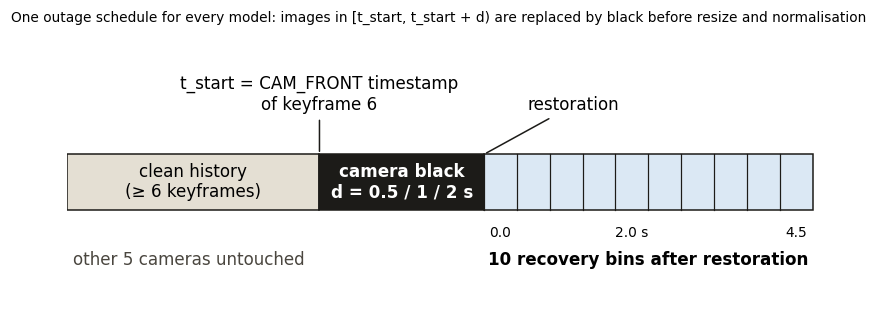

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.0))
ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(-1.6, 3.0)
ax.add_patch(Rectangle((0, 0), 4.6, 1, fc="#e4dfd3", ec="#1c1b18")); ax.text(2.3, .5, "clean history\n(≥ 6 keyframes)", ha="center", va="center")
ax.add_patch(Rectangle((4.6, 0), 3.0, 1, fc="#1c1b18", ec="#1c1b18")); ax.text(6.1, .5, "camera black\nd = 0.5 / 1 / 2 s", ha="center", va="center", color="white", fontweight="bold")
ax.add_patch(Rectangle((7.6, 0), 6.0, 1, fc="#dbe8f4", ec="#1c1b18"))
for i in range(10):
    ax.plot([7.6 + 0.6 * i] * 2, [0, 1], color="#1c1b18", lw=0.8)
for t, lab in ((0, "0.0"), (4, "2.0 s"), (9, "4.5")):
    ax.text(7.9 + 0.6 * t, -0.3, lab, ha="center", va="top", fontsize=9)
ax.text(10.6, -1.0, "10 recovery bins after restoration", ha="center", fontweight="bold")
ax.annotate("t_start = CAM_FRONT timestamp\nof keyframe 6", (4.6, 1), (4.6, 1.8), ha="center", arrowprops=dict(arrowstyle="-", color="#1c1b18"))
ax.annotate("restoration", (7.6, 1), (8.4, 1.8), ha="left", arrowprops=dict(arrowstyle="-", color="#1c1b18"))
ax.text(0.1, -1.0, "other 5 cameras untouched", color="#4a463f")
fig.suptitle("One outage schedule for every model: images in [t_start, t_start + d) are replaced by black before resize and normalisation", fontsize=9, y=0.98)
plt.show()

## 5. A · Recall loss while the camera is black

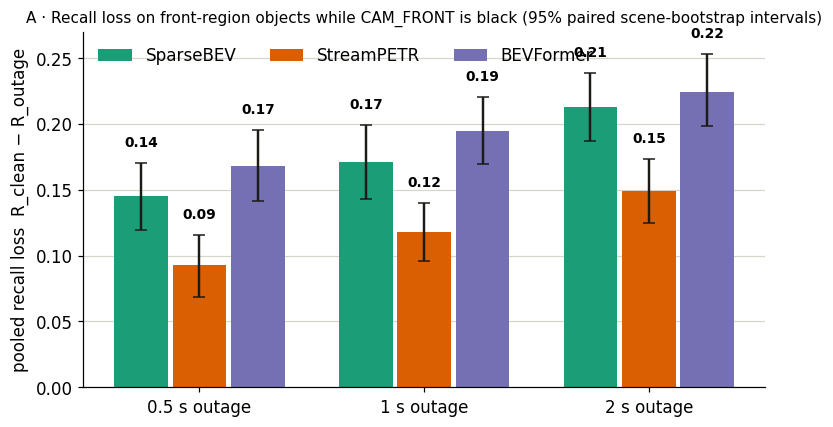

,outage,model,clean recall,outage recall,loss,95% CI,relative loss
0,0.5 s,SparseBEV,0.359,0.215,0.145,"[0.119, 0.170]",0.403
1,0.5 s,StreamPETR,0.316,0.223,0.093,"[0.068, 0.116]",0.293
2,0.5 s,BEVFormer,0.286,0.119,0.168,"[0.141, 0.195]",0.586
3,1 s,SparseBEV,0.360,0.189,0.171,"[0.143, 0.199]",0.475
4,1 s,StreamPETR,0.311,0.193,0.118,"[0.096, 0.140]",0.379
5,1 s,BEVFormer,0.283,0.088,0.194,"[0.170, 0.221]",0.688
6,2 s,SparseBEV,0.356,0.144,0.213,"[0.187, 0.238]",0.597
7,2 s,StreamPETR,0.311,0.162,0.149,"[0.125, 0.173]",0.478
8,2 s,BEVFormer,0.285,0.061,0.224,"[0.198, 0.253]",0.787


In [5]:
def grouped_bars(ax, get, ylim, ylabel, fmt="{:.2f}"):
    """Grouped bars (outage duration x model); get(model, duration) -> (value, lo, hi)."""
    w = 0.26
    for j, (m, lab, c) in enumerate(MODELS):
        xs = np.arange(len(DURS)) + (j - 1) * w
        v = np.array([get(m, d) for d in DURS])
        ax.bar(xs, v[:, 0], w * 0.92, color=c, label=lab)
        ax.errorbar(xs, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none", ecolor="#1c1b18", capsize=4, lw=1.6)
        for x, (val, _, hi) in zip(xs, v):
            ax.text(x, hi + 0.01 * ylim[1] / 0.26, fmt.format(val), ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(range(len(DURS))); ax.set_xticklabels([f"{DLAB[d]} outage" for d in DURS]); ax.set_ylim(*ylim); ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
grouped_bars(ax, lambda m, d: (during[(m, d)]["loss"], *during[(m, d)]["loss_ci95"]), (0, 0.27), "pooled recall loss  R_clean − R_outage")
ax.legend(ncol=3, frameon=False, loc="upper left")
ax.set_title("A · Recall loss on front-region objects while CAM_FRONT is black (95% paired scene-bootstrap intervals)", fontsize=10)
plt.show()

tabA = pd.DataFrame([{"outage": DLAB[d], "model": LABEL[m], "clean recall": during[(m, d)]["recall_clean"], "outage recall": during[(m, d)]["recall_outage"],
                      "loss": during[(m, d)]["loss"], "95% CI": f"[{during[(m, d)]['loss_ci95'][0]:.3f}, {during[(m, d)]['loss_ci95'][1]:.3f}]",
                      "relative loss": during[(m, d)]["relative_loss"]} for d in DURS for m, _, _ in MODELS]).round(3)
tabA

## 6. B · Recovery curves: loss against time after restoration

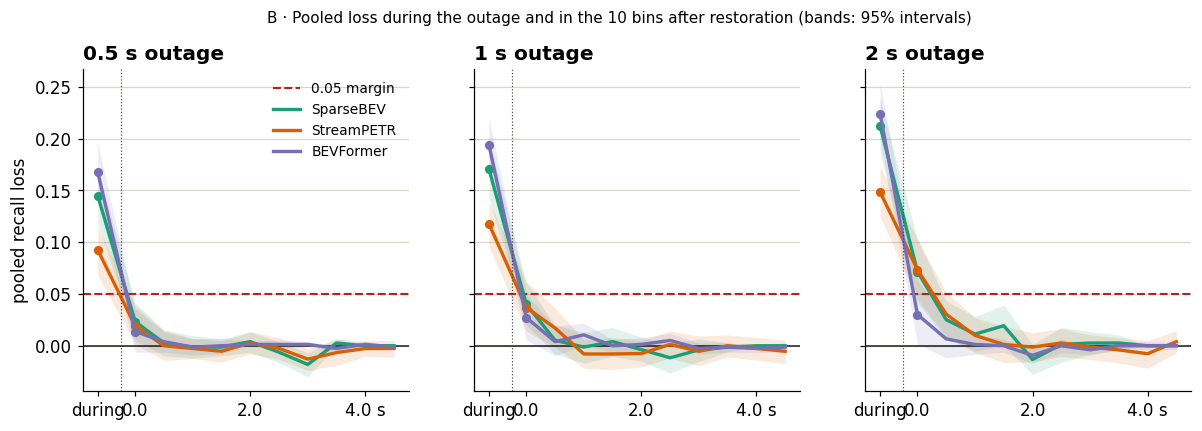

,outage,model,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5
0,0.5 s,SparseBEV,0.023,0.003,-0.001,-0.001,0.004,-0.006,-0.018,0.003,0.000,0.000
1,0.5 s,StreamPETR,0.019,0.000,-0.003,-0.005,0.003,-0.003,-0.013,-0.007,-0.003,-0.003
2,0.5 s,BEVFormer,0.014,0.004,-0.001,0.000,0.001,0.001,0.001,-0.003,0.001,-0.001
3,1 s,SparseBEV,0.040,0.005,-0.001,0.004,-0.004,-0.012,-0.004,-0.001,0.000,0.000
4,1 s,StreamPETR,0.037,0.017,-0.008,-0.008,-0.008,0.001,-0.005,0.000,-0.003,-0.005
5,1 s,BEVFormer,0.027,0.004,0.011,0.000,0.001,0.005,-0.003,-0.001,-0.003,-0.001
6,2 s,SparseBEV,0.072,0.025,0.011,0.019,-0.013,0.001,0.003,0.003,0.000,0.000
7,2 s,StreamPETR,0.074,0.031,0.010,0.001,-0.001,0.003,-0.001,-0.004,-0.008,0.004
8,2 s,BEVFormer,0.030,0.007,0.001,0.000,-0.009,0.000,-0.004,0.000,0.000,0.000


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
x = np.array([-1.3] + list(range(10)))          # "during" sits left of the 10 post-restoration bins
for ax, d in zip(axs, DURS):
    ax.axhline(0, color="#1c1b18", lw=1)
    ax.axhline(0.05, color="#b3261e", lw=1.4, ls="--", label="0.05 margin")
    for m, lab, c in MODELS:
        cur = rs["curves"][m][d]
        y = np.array([cur[p]["loss"] for p in PHASES])
        lo_, hi_ = np.array([cur[p]["loss_ci95"][0] for p in PHASES]), np.array([cur[p]["loss_ci95"][1] for p in PHASES])
        ax.fill_between(x, lo_, hi_, color=c, alpha=0.13, lw=0)
        ax.plot(x, y, color=c, lw=2.2, label=lab)
        ax.plot(x[:2], y[:2], "o", color=c, ms=5)
    ax.axvline(-0.5, color="#4a463f", lw=0.8, ls=":")
    ax.set_xticks([-1.3, 0, 4, 8]); ax.set_xticklabels(["during", "0.0", "2.0", "4.0 s"])
    ax.set_title(f"{DLAB[d]} outage", fontweight="bold", loc="left")
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("pooled recall loss"); axs[0].legend(frameon=False, fontsize=9)
fig.suptitle("B · Pooled loss during the outage and in the 10 bins after restoration (bands: 95% intervals)", fontsize=10, y=1.02)
plt.show()

post = pd.DataFrame([{"outage": DLAB[d], "model": LABEL[m], **{p[1:]: rs["curves"][m][d][p]["loss"] for p in BINS}} for d in DURS for m, _, _ in MODELS]).round(3)
post

## 7. C · Do missed objects come back? (same-object diagnostic)

In [7]:
rows = []
for m, lab, _ in MODELS:
    r = {"model": lab}
    for d in DURS:
        s = so[m][d]["recovered_among_missed_during"]
        r[DLAB[d]] = f"{s['value']:.2f}  ({s['numerator']}/{s['denominator']})"
    rows.append(r)
tabC = pd.DataFrame(rows).set_index("model")
print("share of objects missed during the outage (and detected by the clean run at both samples) that are detected again at the first")
print("strictly later sample with a restored front image; same-sample / still-black pairs are excluded\n")
tabC

share of objects missed during the outage (and detected by the clean run at both samples) that are detected again at the first
strictly later sample with a restored front image; same-sample / still-black pairs are excluded



,0.5 s,1 s,2 s
model,,,
SparseBEV,0.95 (88/93),0.89 (119/133),0.85 (137/161)
StreamPETR,0.87 (61/70),0.80 (78/98),0.70 (89/127)
BEVFormer,0.89 (85/96),0.88 (119/136),0.82 (120/147)


## 8. D · Per-event damage rate

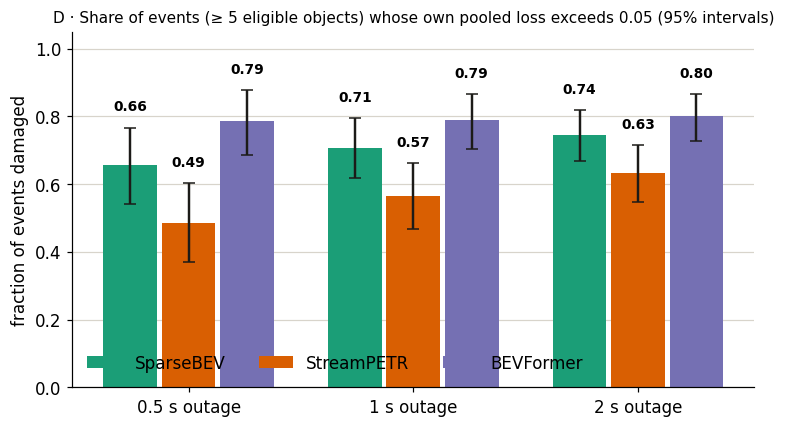

,outage,pair,damage-rate difference,95% CI,interval excludes 0
0,0.5 s,sparsebev − streampetr,0.171,"[0.03, 0.31]",True
1,0.5 s,sparsebev − bevformer,-0.129,"[-0.26, 0.00]",False
2,0.5 s,streampetr − bevformer,-0.300,"[-0.44, -0.16]",True
3,1 s,sparsebev − streampetr,0.141,"[0.05, 0.24]",True
4,1 s,sparsebev − bevformer,-0.081,"[-0.18, 0.01]",False
5,1 s,streampetr − bevformer,-0.222,"[-0.32, -0.13]",True
6,2 s,sparsebev − streampetr,0.112,"[0.04, 0.18]",True
7,2 s,sparsebev − bevformer,-0.056,"[-0.14, 0.02]",False
8,2 s,streampetr − bevformer,-0.168,"[-0.25, -0.09]",True


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
get = lambda m, d: (lambda e: (e["value"], *e["ci95"]))(rs["events"][m][d]["damage_rate_among_sufficient"])
grouped_bars(ax, get, (0, 1.05), "fraction of events damaged")
ax.legend(ncol=3, frameon=False, loc="lower left")
ax.set_title("D · Share of events (≥ 5 eligible objects) whose own pooled loss exceeds 0.05 (95% intervals)", fontsize=10)
plt.show()

pw = pd.DataFrame([{"outage": DLAB[d], "pair": k.replace("_minus_", " − "), "damage-rate difference": v["damage_rate_difference"]["value"],
                    "95% CI": f"[{v['damage_rate_difference']['ci95'][0]:.2f}, {v['damage_rate_difference']['ci95'][1]:.2f}]",
                    "interval excludes 0": not (v["damage_rate_difference"]["ci95"][0] <= 0 <= v["damage_rate_difference"]["ci95"][1])}
                   for d in DURS for k, v in rs["pairwise"][d].items()]).round(3)
pw

## 9. E · Per-event recovery is mostly censored

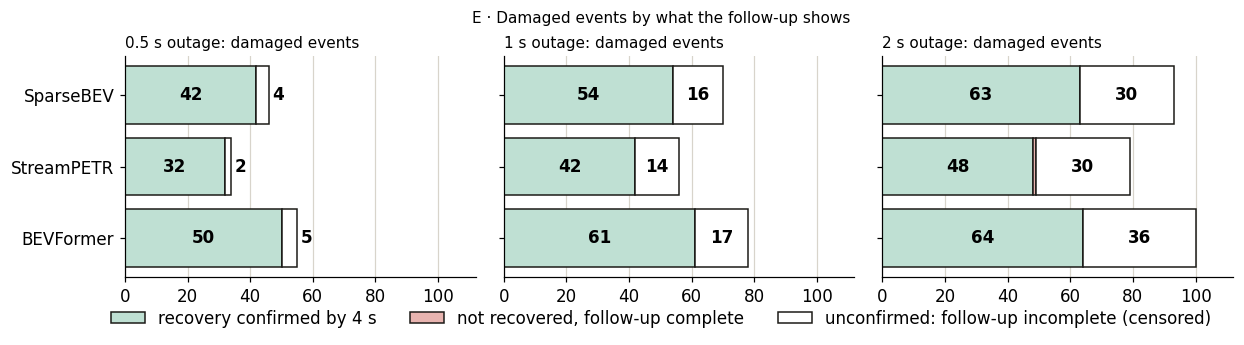

,outage,model,events,insufficient data,damaged,confirmed by 4 s,complete follow-up,confirmed | complete,incomplete share
0,0.5 s,SparseBEV,150,80,46,42/46,26,26,0.43
1,0.5 s,StreamPETR,150,80,34,32/34,19,19,0.44
2,0.5 s,BEVFormer,150,80,55,50/55,29,29,0.47
3,1 s,SparseBEV,150,51,70,54/70,27,27,0.61
4,1 s,StreamPETR,150,51,56,42/56,16,16,0.71
5,1 s,BEVFormer,150,51,78,61/78,27,27,0.65
6,2 s,SparseBEV,150,25,93,63/93,22,22,0.76
7,2 s,StreamPETR,150,25,79,48/79,18,17,0.77
8,2 s,BEVFormer,150,25,100,64/100,26,26,0.74


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(13, 2.6), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, d in zip(axs, DURS):
    for k, (m, lab, c) in enumerate(MODELS):
        e = rs["events"][m][d]
        conf = e["confirmed_onset_by_4s_among_damaged"]["numerator"]
        comp = e["category_counts"]["damaged_no_confirmed_recovery_complete_followup"]
        unc = e["category_counts"]["damaged_unconfirmed_incomplete_followup"]
        assert conf + comp + unc == e["n_damaged"]
        y = len(MODELS) - 1 - k
        ax.barh(y, conf, color="#bfe0d3", ec="#1c1b18", label="recovery confirmed by 4 s")
        ax.barh(y, comp, left=conf, color="#e8b4b0", ec="#1c1b18", label="not recovered, follow-up complete")
        ax.barh(y, unc, left=conf + comp, color="white", ec="#1c1b18", label="unconfirmed: follow-up incomplete (censored)")
        ax.text(conf / 2, y, str(conf), ha="center", va="center", fontweight="bold")
        if unc >= 8:
            ax.text(conf + comp + unc / 2, y, str(unc), ha="center", va="center", fontweight="bold")
        else:
            ax.text(conf + comp + unc + 1, y, str(unc), ha="left", va="center", fontweight="bold")
    ax.set_yticks(range(len(MODELS))); ax.set_yticklabels([LABEL[m] for m, _, _ in reversed(MODELS)]); ax.set_xlim(0, 112)
    ax.set_title(f"{DLAB[d]} outage: damaged events", fontsize=10, loc="left"); ax.grid(axis="y", visible=False)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles[:3], labels[:3], ncol=3, loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("E · Damaged events by what the follow-up shows", fontsize=10, y=1.04)
plt.show()

ev = pd.DataFrame([{"outage": DLAB[d], "model": LABEL[m], "events": rs["events"][m][d]["n_events"], "insufficient data": rs["events"][m][d]["category_counts"]["insufficient_data"],
                    "damaged": rs["events"][m][d]["n_damaged"],
                    "confirmed by 4 s": f"{rs['events'][m][d]['confirmed_onset_by_4s_among_damaged']['numerator']}/{rs['events'][m][d]['confirmed_onset_by_4s_among_damaged']['denominator']}",
                    "complete follow-up": rs["events"][m][d]["damaged_with_complete_followup"]["n"],
                    "confirmed | complete": rs["events"][m][d]["damaged_with_complete_followup"]["confirmed_onset"],
                    "incomplete share": rs["events"][m][d]["damaged_with_complete_followup"]["share_of_damaged_with_incomplete_followup"]["value"]}
                   for d in DURS for m, _, _ in MODELS]).round(2)
ev

## 10. Cost on an RTX 3060 (12 GB), batch 1

In [10]:
cost = pd.DataFrame([{"Model": LABEL[m], "Latency (ms, median)": round(profile[m]["latency_ms"]["steady_median"]),
                      "Peak allocated GPU (MB)": round(profile[m]["peak_allocated_mb"]),
                      "CPU decode (ms)": round(profile[m]["data_loading_cpu_ms"]["median"]),
                      "Paired end-to-end (ms)": round(profile[m]["end_to_end_ms_paired_median"])} for m, _, _ in MODELS]).set_index("Model")
cost

,"Latency (ms, median)",Peak allocated GPU (MB),CPU decode (ms),Paired end-to-end (ms)
Model,,,,
SparseBEV,190,2652,209,403
StreamPETR,79,375,152,231
BEVFormer,131,617,151,284


## 11a. Paired uncertainty for the precision change

Precision during the outage minus precision in the paired clean run, with the same paired scene bootstrap as everywhere else (same weight matrix, B = 10,000, seed 535).
Separate clean and outage intervals cannot test this difference, because the two runs share scenes; the interval of the *difference* can.

In [11]:
import sys
sys.path.insert(0, str(ROOT / "RecoveryAnalysis"))
from recovery import stats as rstats, data as rdata
_ms = rdata.load_all()
_S = len(_ms["sparsebev"]["scenes"]); _W = rstats.weights(_S, rstats.B_DEFAULT, rstats.SEED); _j = rdata.PHASES.index("during")
dprec = {}
for m in LABEL:
    for d in DURS:
        arr = _ms[m]["by_duration"][float(d)]
        pt = rstats.pooled(arr, np.ones((1, _S))); bs = rstats.pooled(arr, _W)
        delta_pt = pt["precision_outage"][0, _j] - pt["precision_clean"][0, _j]
        delta_bs = bs["precision_outage"][:, _j] - bs["precision_clean"][:, _j]
        lo_, hi_ = np.nanpercentile(delta_bs, [2.5, 97.5])
        dprec[(m, d)] = (float(delta_pt), float(lo_), float(hi_))
tabP = pd.DataFrame([{"outage": DLAB[d], "model": LABEL[m], "precision clean": rs["curves"][m][d]["during"]["precision_clean"], "precision outage": rs["curves"][m][d]["during"]["precision_outage"],
                      "paired change": dprec[(m, d)][0], "95% CI": f"[{dprec[(m, d)][1]:.3f}, {dprec[(m, d)][2]:.3f}]", "excludes 0": not (dprec[(m, d)][1] <= 0 <= dprec[(m, d)][2]),
                      "FP clean": rs["curves"][m][d]["during"]["false_positives_clean"], "FP outage": rs["curves"][m][d]["during"]["false_positives_outage"]}
                     for d in DURS for m, _, _ in MODELS]).round(3)
tabP

,outage,model,precision clean,precision outage,paired change,95% CI,excludes 0,FP clean,FP outage
0,0.5 s,SparseBEV,0.935,0.938,0.003,"[-0.038, 0.045]",False,23,13
1,0.5 s,StreamPETR,0.929,0.869,-0.061,"[-0.102, -0.023]",True,22,31
2,0.5 s,BEVFormer,0.895,0.872,-0.023,"[-0.082, 0.029]",False,31,16
3,1 s,SparseBEV,0.938,0.897,-0.040,"[-0.089, 0.003]",False,42,38
4,1 s,StreamPETR,0.925,0.848,-0.078,"[-0.121, -0.039]",True,44,61
5,1 s,BEVFormer,0.900,0.876,-0.024,"[-0.083, 0.025]",False,55,22
6,2 s,SparseBEV,0.940,0.868,-0.072,"[-0.120, -0.032]",True,77,74
7,2 s,StreamPETR,0.922,0.846,-0.076,"[-0.120, -0.035]",True,89,100
8,2 s,BEVFormer,0.902,0.899,-0.003,"[-0.052, 0.037]",False,104,23


## 11. Does the poster's text match the data?

Each statement printed on the poster is re-derived from the loaded results; the cell raises an error if any of them no longer holds.

In [12]:
checks = []
def check(text, ok):
    checks.append((text, bool(ok)))

check("every model loses recall during the outage: all 9 intervals exclude zero", (lo > 0).all())
check("loss during the outage ranges 0.09 – 0.22", round(loss.min(), 2) == 0.09 and round(loss.max(), 2) == 0.22)
check("relative loss ranges 29 – 79 %", round(100 * rel.min()) == 29 and round(100 * rel.max()) == 79)
check("StreamPETR loses least, BEVFormer most (every duration)",
      all(during[("streampetr", d)]["loss"] < during[("sparsebev", d)]["loss"] < during[("bevformer", d)]["loss"] for d in DURS))
check("0.0 s after 2 s outages: SparseBEV 0.072, StreamPETR 0.074 (above the 0.05 margin)",
      round(rs["curves"]["sparsebev"]["2.0"]["b0.0"]["loss"], 3) == 0.072 and round(rs["curves"]["streampetr"]["2.0"]["b0.0"]["loss"], 3) == 0.074)
exceptions = {("sparsebev", "2.0"), ("streampetr", "2.0")}
check("all other first bins are inside the 0.05 margin", all(rs["curves"][m][d]["b0.0"]["loss"] <= 0.05 for m in LABEL for d in DURS if (m, d) not in exceptions))
check("from 0.5 s on, every pooled |loss| ≤ 0.031", max(abs(rs["curves"][m][d][p]["loss"]) for m in LABEL for d in DURS for p in BINS[1:]) <= 0.0315)
check("SparseBEV: no positive loss at 3.0 – 4.0 s (interval upper bound ≤ 0.015)", max(c[1] for c in late) <= 0.015)
dr = {(m, d): rs["events"][m][d]["damage_rate_among_sufficient"]["value"] for m in LABEL for d in DURS}
check("damage rates SparseBEV 0.66/0.71/0.74, StreamPETR 0.49/0.57/0.63, BEVFormer 0.79/0.79/0.80",
      [round(dr[("sparsebev", d)], 2) for d in DURS] == [0.66, 0.71, 0.74] and [round(dr[("streampetr", d)], 2) for d in DURS] == [0.49, 0.57, 0.63]
      and [round(dr[("bevformer", d)], 2) for d in DURS] == [0.79, 0.79, 0.80])
check("StreamPETR has the lowest damage rate at every duration", all(dr[("streampetr", d)] < min(dr[("sparsebev", d)], dr[("bevformer", d)]) for d in DURS))
check("SparseBEV vs BEVFormer damage rate: no statistically detected difference (every interval reaches zero)",
      all(rs["pairwise"][d]["sparsebev_minus_bevformer"]["damage_rate_difference"]["ci95"][0] <= 0 <= rs["pairwise"][d]["sparsebev_minus_bevformer"]["damage_rate_difference"]["ci95"][1] for d in DURS))
check("43 – 77 % of damaged events have incomplete follow-up", round(100 * incomplete.min()) == 43 and round(100 * incomplete.max()) == 77)
cf = [rs["events"][m][d]["damaged_with_complete_followup"] for m in LABEL for d in DURS]
check("recovery confirmed in 209 of 210 complete-follow-up events", (sum(x["confirmed_onset"] for x in cf), sum(x["n"] for x in cf)) == (209, 210))
check("2 s outage damaged events 93 / 79 / 100 (SparseBEV / StreamPETR / BEVFormer)", [rs["events"][m]["2.0"]["n_damaged"] for m in LABEL] == [93, 79, 100])
check("same-object shares 0.95/0.89/0.85, 0.87/0.80/0.70, 0.89/0.88/0.82",
      [round(so["sparsebev"][d]["recovered_among_missed_during"]["value"], 2) for d in DURS] == [0.95, 0.89, 0.85]
      and [round(so["streampetr"][d]["recovered_among_missed_during"]["value"], 2) for d in DURS] == [0.87, 0.80, 0.70]
      and [round(so["bevformer"][d]["recovered_among_missed_during"]["value"], 2) for d in DURS] == [0.89, 0.88, 0.82])
check("latency 190 / 79 / 131 ms and peak memory 2,652 / 375 / 617 MB (SparseBEV / StreamPETR / BEVFormer)",
      [round(profile[m]["latency_ms"]["steady_median"]) for m in LABEL] == [190, 79, 131] and [round(profile[m]["peak_allocated_mb"]) for m in LABEL] == [2652, 375, 617])
check("paired precision change at 2 s: SparseBEV -0.072 and StreamPETR -0.076 (intervals exclude 0), BEVFormer -0.003 (includes 0)",
      [round(dprec[(m, "2.0")][0], 3) for m in LABEL] == [-0.072, -0.076, -0.003] and dprec[("sparsebev", "2.0")][2] < 0 and dprec[("streampetr", "2.0")][2] < 0 and dprec[("bevformer", "2.0")][1] < 0 < dprec[("bevformer", "2.0")][2])
check("StreamPETR false positives rise 89 -> 100 and SparseBEV 77 -> 74 at 2 s",
      (rs["curves"]["streampetr"]["2.0"]["during"]["false_positives_clean"], rs["curves"]["streampetr"]["2.0"]["during"]["false_positives_outage"], rs["curves"]["sparsebev"]["2.0"]["during"]["false_positives_clean"], rs["curves"]["sparsebev"]["2.0"]["during"]["false_positives_outage"]) == (89, 100, 77, 74))
check("StreamPETR 2 s: 89/127 missed-during objects detected again, 38 of them (30%) still missed = 21% of 185 continuing clean-detected objects",
      (lambda s_: (s_["numerator"], s_["denominator"], so["streampetr"]["2.0"]["counts"]["cont_missed_d_missed_after"], so["streampetr"]["2.0"]["counts"]["continuing_clean_detected_both"]))(so["streampetr"]["2.0"]["recovered_among_missed_during"]) == (89, 127, 38, 185))
check("SparseBEV late bins (3.0-4.0 s): largest interval upper bound is 0.014", round(max(c[1] for c in late), 3) == 0.014)
check("clean NDS within ±0.010 of the released values", (det["|diff|"] <= 0.010).all())

report = pd.DataFrame(checks, columns=["statement on the poster", "holds"])
assert report["holds"].all(), report[~report["holds"]]
report

,statement on the poster,holds
0,every model loses recall during the outage: al...,True
1,loss during the outage ranges 0.09 – 0.22,True
2,relative loss ranges 29 – 79 %,True
3,"StreamPETR loses least, BEVFormer most (every ...",True
4,"0.0 s after 2 s outages: SparseBEV 0.072, Stre...",True
5,all other first bins are inside the 0.05 margin,True
6,"from 0.5 s on, every pooled |loss| ≤ 0.031",True
7,SparseBEV: no positive loss at 3.0 – 4.0 s (in...,True
8,"damage rates SparseBEV 0.66/0.71/0.74, StreamP...",True
9,StreamPETR has the lowest damage rate at every...,True


## 12. Figures for the paper (`figures/*.pdf`)

The IEEE conference paper in this folder (`paper.tex`) uses the three figures written here, at column width. Fonts are embedded as TrueType (no Type 3 fonts).

In [13]:
FIG = ROOT / "Report" / "figures"; FIG.mkdir(exist_ok=True)
paper = {"font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
         "pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "serif", "font.serif": ["DejaVu Serif"], "axes.linewidth": 0.6,
         "xtick.major.width": 0.6, "ytick.major.width": 0.6, "grid.linewidth": 0.4}
CI = lambda ci: (ci[0], ci[1])

# ---- Fig. 1: protocol timeline (one column)
with plt.rc_context(paper):
    fig, ax = plt.subplots(figsize=(3.45, 1.15)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(-1.5, 2.6)
    ax.add_patch(Rectangle((0, 0), 4.6, 1, fc="#e4dfd3", ec="k", lw=0.6)); ax.text(2.3, .5, "clean history\n($\\geq$6 keyframes)", ha="center", va="center", fontsize=6)
    ax.add_patch(Rectangle((4.6, 0), 3.0, 1, fc="k", ec="k", lw=0.6)); ax.text(6.1, .5, "camera\nblack", ha="center", va="center", color="w", fontsize=6.5)
    ax.add_patch(Rectangle((7.6, 0), 6.0, 1, fc="#dbe8f4", ec="k", lw=0.6))
    for i in range(1, 10): ax.plot([7.6 + 0.6 * i] * 2, [0, 1], color="k", lw=0.4)
    for t, lab in ((0, "0.0"), (4, "2.0"), (9, "4.5 s")): ax.text(7.9 + 0.6 * t, -0.25, lab, ha="center", va="top", fontsize=6)
    ax.text(10.6, -1.15, "10 recovery bins", ha="center", fontsize=6.5, fontweight="bold")
    ax.annotate("$t_{start}$ = CAM_FRONT time\nof keyframe 6", (4.6, 1), (3.2, 1.9), ha="center", fontsize=6, arrowprops=dict(arrowstyle="-", lw=0.5))
    ax.annotate("restoration", (7.6, 1), (9.4, 1.9), ha="left", fontsize=6, arrowprops=dict(arrowstyle="-", lw=0.5))
    fig.savefig(FIG / "fig_protocol.pdf", bbox_inches="tight", pad_inches=0.02); plt.close(fig)

# ---- Fig. 2: loss during the outage (bars) + recovery curves (two columns)
with plt.rc_context(paper):
    fig, axs = plt.subplots(1, 4, figsize=(7.16, 1.75), gridspec_kw={"width_ratios": [1.15, 1, 1, 1], "wspace": 0.28})
    ax = axs[0]; w = 0.27
    for j, (m, lab, c) in enumerate(MODELS):
        xs = np.arange(3) + (j - 1) * w
        v = np.array([(during[(m, d)]["loss"], *during[(m, d)]["loss_ci95"]) for d in DURS])
        ax.bar(xs, v[:, 0], w * 0.92, color=c, label=lab)
        ax.errorbar(xs, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none", ecolor="k", capsize=1.5, lw=0.7)
    ax.set_xticks(range(3)); ax.set_xticklabels(["0.5 s", "1 s", "2 s"]); ax.set_ylabel("pooled recall loss"); ax.set_ylim(0, 0.27)
    ax.set_title("(a) during the outage", loc="left"); ax.grid(axis="x", visible=False)
    x = np.array([-1.3] + list(range(10)))
    for ax, d, tag in zip(axs[1:], DURS, "bcd"):
        ax.axhline(0, color="k", lw=0.6); ax.axhline(0.05, color="#b3261e", lw=0.8, ls="--")
        for m, lab, c in MODELS:
            cur = rs["curves"][m][d]
            y = np.array([cur[p]["loss"] for p in PHASES]); l_ = np.array([cur[p]["loss_ci95"][0] for p in PHASES]); h_ = np.array([cur[p]["loss_ci95"][1] for p in PHASES])
            ax.fill_between(x, l_, h_, color=c, alpha=0.12, lw=0); ax.plot(x, y, color=c, lw=1.1); ax.plot(x[:2], y[:2], "o", color=c, ms=2)
        ax.axvline(-0.5, color="0.4", lw=0.5, ls=":"); ax.set_xticks([-1.3, 0, 4, 8]); tl = ax.set_xticklabels(["during", "0.0", "2.0", "4.0 s"]); tl[0].set_ha("right"); tl[1].set_ha("left")
        if tag == "b": ax.legend(handles=[plt.Line2D([], [], color=c, lw=1.2, label=lab) for _, lab, c in MODELS], frameon=False, loc="upper right", handlelength=1)
        ax.set_ylim(-0.04, 0.27); ax.set_yticklabels([]); ax.set_title(f"({tag}) {DLAB[d]} outage", loc="left"); ax.grid(axis="x", visible=False)
    fig.savefig(FIG / "fig_results.pdf", bbox_inches="tight", pad_inches=0.02); plt.close(fig)

# ---- Fig. 3: failure modes (two columns)
pc = load("analysis", "classes_sameobject.json")["per_class"]
with plt.rc_context(paper):
    fig, axs = plt.subplots(1, 3, figsize=(7.16, 1.75), gridspec_kw={"width_ratios": [1, 1, 1.35], "wspace": 0.32})
    ax = axs[0]
    for m, lab, c in MODELS:
        v = np.array([(so[m][d]["persisting_miss_fraction_of_continuing_clean_detected"]["value"], *so[m][d]["persisting_miss_fraction_of_continuing_clean_detected"]["ci95"]) for d in DURS])
        ax.errorbar(np.arange(3), v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], color=c, marker="o", ms=2.5, lw=1, capsize=1.5, label=lab)
    ax.set_xticks(range(3)); ax.set_xticklabels(["0.5 s", "1 s", "2 s"]); ax.set_ylim(0, 0.32); ax.set_ylabel("share still missed")
    ax.set_title("(a) persisting misses", loc="left"); ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper left", handlelength=1)
    ax = axs[1]; w = 0.27
    for j, (m, lab, c) in enumerate(MODELS):
        xs = np.arange(3) + (j - 1) * w
        v = np.array([dprec[(m, d)] for d in DURS])
        ax.bar(xs, v[:, 0], w * 0.92, color=c); ax.errorbar(xs, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none", ecolor="k", capsize=1.5, lw=0.7)
    ax.axhline(0, color="k", lw=0.6); ax.set_xticks(range(3)); ax.set_xticklabels(["0.5 s", "1 s", "2 s"]); ax.set_ylabel("$\Delta$ precision")
    ax.set_title("(b) paired precision change", loc="left"); ax.grid(axis="x", visible=False)
    ax = axs[2]; classes = ["car", "truck", "barrier", "pedestrian", "traffic_cone"]; w = 0.27
    for j, (m, lab, c) in enumerate(MODELS):
        r_ = pc[m]["2.0"]["during"]
        v = np.array([(r_[k]["loss"], *r_[k]["loss_ci95"]) for k in classes])
        xs = np.arange(len(classes)) + (j - 1) * w
        ax.bar(xs, v[:, 0], w * 0.92, color=c); ax.errorbar(xs, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none", ecolor="k", capsize=1.2, lw=0.6)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(["car", "truck", "barrier", "ped.", "cone"]); ax.set_ylabel("recall loss, 2 s outage")
    ax.set_title("(c) per class (n $\\geq$ 200)", loc="left"); ax.grid(axis="x", visible=False)
    fig.savefig(FIG / "fig_failure.pdf", bbox_inches="tight", pad_inches=0.02); plt.close(fig)

# ---- Fig. 4: qualitative example (cropped copy of the rule-selected SparseBEV event)
img = plt.imread(ART / "figures" / "qualitative" / "qual_sparsebev_recovered_first_bin.png")
h, w_ = img.shape[:2]
plt.imsave(FIG / "fig_qualitative.png", img[int(0.13 * h):int(0.95 * h), int(0.0 * w_):])
print(sorted(p.name for p in FIG.iterdir()))

['fig_failure.pdf', 'fig_protocol.pdf', 'fig_qualitative.png', 'fig_results.pdf']
